

DATASET 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, RocCurveDisplay

from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show


In [2]:
#PREPROCESING DEI DATI

column_names = [
    'Status_Checking_Account', 'Duration_Months', 'Credit_History', 'Purpose',
    'Credit_Amount', 'Savings_Account_Bonds', 'Employment_Since',
    'Installment_Rate', 'Personal_Status_Sex', 'Other_Debtors',
    'Present_Residence_Since', 'Property', 'Age', 'Other_Installment_Plans',
    'Housing', 'Number_Credits', 'Job', 'People_Liable',
    'Telephone', 'Foreign_Worker', 'class'
]


df = pd.read_csv("dataset1.data", sep=' ', header=None, names=column_names)


#  Dimensione del dataset
print(" Numero di osservazioni e variabili:")
print(f"Righe (osservazioni): {df.shape[0]}")
print(f"Colonne (variabili): {df.shape[1]}")
print()

#  Tipologia delle variabili
print(" Tipi di variabili:")
print(df.dtypes.value_counts())
print()
print("Esempio di variabili per tipo:")
print(df.dtypes.head(10))
print()

# Check Valori mancanti
print(" Valori mancanti per variabile:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if missing.empty:
    print(" Nessun valore mancante nel dataset.")
else:
    print(missing)
print()

# Sbilanciamento del target
print(" Distribuzione della variabile target 'class':")
print(df['class'].value_counts())
print("Distribuzione percentuale:")
print(df['class'].value_counts(normalize=True).apply(lambda x: f"{x:.2%}"))
print()

#  Statistiche descrittive numeriche
print("📌 Statistiche descrittive delle variabili numeriche:")
display(df.describe())

# 6. Statistiche descrittive categoriche 
categorical = df.select_dtypes(include=['object', 'category']).columns
if len(categorical) > 0:
    print("📌 Statistiche delle variabili categoriche:")
    display(df[categorical].describe())
else:
    print(" Nessuna variabile categorica esplicita nel formato object/category.")




 Numero di osservazioni e variabili:
Righe (osservazioni): 1000
Colonne (variabili): 21

 Tipi di variabili:
object    13
int64      8
Name: count, dtype: int64

Esempio di variabili per tipo:
Status_Checking_Account    object
Duration_Months             int64
Credit_History             object
Purpose                    object
Credit_Amount               int64
Savings_Account_Bonds      object
Employment_Since           object
Installment_Rate            int64
Personal_Status_Sex        object
Other_Debtors              object
dtype: object

 Valori mancanti per variabile:
 Nessun valore mancante nel dataset.

 Distribuzione della variabile target 'class':
class
1    700
2    300
Name: count, dtype: int64
Distribuzione percentuale:
class
1    70.00%
2    30.00%
Name: proportion, dtype: object

📌 Statistiche descrittive delle variabili numeriche:


,Duration_Months,Credit_Amount,Installment_Rate,Present_Residence_Since,Age,Number_Credits,People_Liable,class
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000


📌 Statistiche delle variabili categoriche:


,Status_Checking_Account,Credit_History,Purpose,Savings_Account_Bonds,Employment_Since,Personal_Status_Sex,Other_Debtors,Property,Other_Installment_Plans,Housing,Job,Telephone,Foreign_Worker
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,4,5,10,5,5,4,3,4,3,3,4,2,2
top,A14,A32,A43,A61,A73,A93,A101,A123,A143,A152,A173,A191,A201
freq,394,530,280,603,339,548,907,332,814,713,630,596,963


In [3]:
# Ricodifica Variabili qualitative

#1. Status of checking account
map_status_checking = {
    "A11": "<0 DM",
    "A12": "0-200 DM",
    "A13": ">=200 DM / salary",
    "A14": "no account"
}

# 2. Credit history
map_credit_history = {
    "A30": "no credits",
    "A31": "all paid",
    "A32": "current paid",
    "A33": "delays",
    "A34": "critical/other credits"
}

# 3. Purpose
map_purpose = {
    "A40": "car new",
    "A41": "car used",
    "A42": "furniture",
    "A43": "radio/TV",
    "A44": "appliances",
    "A45": "repairs",
    "A46": "education",
    "A47": "vacation",
    "A48": "retraining",
    "A49": "business",
    "A410": "other"
}

# 4. Savings account/bonds
map_savings = {
    "A61": "<100 DM",
    "A62": "100-500 DM",
    "A63": "500-1000 DM",
    "A64": ">=1000 DM",
    "A65": "unknown/none"
}

# 5. Employment since
map_employment = {
    "A71": "unemployed",
    "A72": "<1 year",
    "A73": "1-4 years",
    "A74": "4-7 years",
    "A75": ">=7 years"
}

# 6. Personal status & sex
map_personal = {
    "A91": "male-divorced",
    "A92": "male-single",
    "A93": "male-married",
    "A94": "female-divorced/married",
    "A95": "female-single"
}

# 7. Other debtors/guarantors
map_debtors = {
    "A101": "none",
    "A102": "co-applicant",
    "A103": "guarantor"
}

# 8. Property
map_property = {
    "A121": "real estate",
    "A122": "savings/life ins.",
    "A123": "car/other",
    "A124": "unknown/none"
}

# 9. Other installment plans
map_installment = {
    "A141": "none",
    "A142": "bank",
    "A143": "stores"
}

# 10. Housing
map_housing = {
    "A151": "rent",
    "A152": "own",
    "A153": "free"
}

# 11. Job
map_job = {
    "A171": "unemployed/unskilled-nonres",
    "A172": "unskilled-resident",
    "A173": "skilled",
    "A174": "high qual./self-emp."
}

# 12. Telephone
map_phone = {
    "A191": "no",
    "A192": "yes"
}

# 13. Foreign worker
map_foreign = {
    "A201": "yes",
    "A202": "no"
}

df["Status_Checking_Account"] = df["Status_Checking_Account"].replace(map_status_checking)
df["Credit_History"] = df["Credit_History"].replace(map_credit_history)
df["Purpose"] = df["Purpose"].replace(map_purpose)
df["Savings_Account_Bonds"] = df["Savings_Account_Bonds"].replace(map_savings)
df["Employment_Since"] = df["Employment_Since"].replace(map_employment)
df["Personal_Status_Sex"] = df["Personal_Status_Sex"].replace(map_personal)
df["Other_Debtors"] = df["Other_Debtors"].replace(map_debtors)
df["Property"] = df["Property"].replace(map_property)
df["Other_Installment_Plans"] = df["Other_Installment_Plans"].replace(map_installment)
df["Housing"] = df["Housing"].replace(map_housing)
df["Job"] = df["Job"].replace(map_job)
df["Telephone"] = df["Telephone"].replace(map_phone)
df["Foreign_Worker"] = df["Foreign_Worker"].replace(map_foreign)


In [4]:
# assegnazione di Etichette a variabili considerate numeriche ma che non lo sono

map_installment_rate = {
    1: "~20% income",
    2: "~25% income",
    3: "~30% income",
    4: "~35% income"
}
map_residence = {
    1: "<1 year",
    2: "1-2 years",
    3: "2-4 years",
    4: ">=4 years"
}
map_num_credits = {
    1: "1 credit",
    2: "2 credits",
    3: "3 credits",
    4: ">=4 credits"
}
map_people_liable = {
    1: "1 person",
    2: ">=2 persons"
}

#mapping alle variabili discrete
df["Installment_Rate"] = df["Installment_Rate"].replace(map_installment_rate)
df["Present_Residence_Since"] = df["Present_Residence_Since"].replace(map_residence)
df["Number_Credits"] = df["Number_Credits"].replace(map_num_credits)
df["People_Liable"] = df["People_Liable"].replace(map_people_liable)

In [7]:
#Report Generato da Ydata_profiling

import pandas as pd
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Profilo German Credit Dataset", explorative=True)
profile.to_notebook_iframe()


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21/21 [00:00<00:00, 344064.00it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [5]:
# Elimino le due variabili dal dataset: una per forte associazione, l'altra per problemi di discriminazione
df = df.drop(columns=["Housing", "Foreign_Worker"])

# Controllo che siano state rimosse
print(df.columns)


Index(['Status_Checking_Account', 'Duration_Months', 'Credit_History',
       'Purpose', 'Credit_Amount', 'Savings_Account_Bonds', 'Employment_Since',
       'Installment_Rate', 'Personal_Status_Sex', 'Other_Debtors',
       'Present_Residence_Since', 'Property', 'Age', 'Other_Installment_Plans',
       'Number_Credits', 'Job', 'People_Liable', 'Telephone', 'class'],
      dtype='object')


In [6]:
####EXPLAINABLE BOOSTING MACHINE ########################

from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.model_selection import train_test_split

# ricodifica target 0/1
df["default"] = df["class"].map({1: 0, 2: 1})
X = df.drop(columns=["class", "default"])   # tutte le feature originali (categoriche incluse)
y = df["default"]

#split in test e train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

In [7]:
from interpret.glassbox import ExplainableBoostingClassifier

ebm_standard = ExplainableBoostingClassifier(
    # >>>  DEFAULT  versione pacchetto EBM 0.5.0  <<<
    random_state        = 42,      
    learning_rate       = 0.01,    
    max_leaves          = 2,       
    max_bins            = 64,     
    min_samples_leaf    = 10,       
    outer_bags          = 8,       
    inner_bags          = 0,       
    interactions        = 10,      
    max_interaction_bins= 32,     
    early_stopping_rounds   = 400, 
    early_stopping_tolerance= 1e-4,
    feature_names       = None,    
    feature_types       = None,
    n_jobs              = None,    
    missing             = "gain",  
)

ebm_standard.fit(X_train, y_train)
y_pred_ebm  = ebm_standard.predict(X_test)
y_prob_ebm  = ebm_standard.predict_proba(X_test)[:, 1]

In [8]:
### GRAFICI INTERATTIVI DI EBM

from interpret import show
print(" EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm))
print("AUC:", roc_auc_score(y_test, y_prob_ebm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ebm))

# spiegazioni globali dal modello EBM 
ebm_global = ebm_standard.explain_global()
show(ebm_global)

 
####  2 semplificare il modello, 1000 osservazioni così è troppo complesso

 EBM
Accuracy: 0.78
AUC: 0.8129100529100529
Confusion Matrix:
 [[192  18]
 [ 48  42]]


<!-- http://127.0.0.1:7885/4499889840/ -->

In [9]:
#EBM base senza interazioni

from interpret.glassbox import ExplainableBoostingClassifier

ebm3 = ExplainableBoostingClassifier(
     
    random_state        = 42,      # stesso seed di sempre
    interactions        = 0,
)

ebm3.fit(X_train, y_train)
y_pred_ebm  = ebm3.predict(X_test)
y_prob_ebm  = ebm3.predict_proba(X_test)[:, 1]

ebm3.fit(X_train, y_train)
y_pred_ebm  = ebm3.predict(X_test)
y_prob_ebm  = ebm3.predict_proba(X_test)[:, 1]

print("\n EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm))
print("AUC:", roc_auc_score(y_test, y_prob_ebm))



 EBM
Accuracy: 0.7833333333333333
AUC: 0.8105291005291005


In [10]:
#modello con  early stopping, learning rate e validation size per ridurre la varianza delle stime:

from interpret.glassbox import ExplainableBoostingClassifier

ebm4 = ExplainableBoostingClassifier(
    
    random_state        = 42,
    learning_rate=0.02,
    validation_size=0.2,
    early_stopping_rounds=10
)


ebm4.fit(X_train, y_train)
y_pred_ebm  = ebm4.predict(X_test)
y_prob_ebm  = ebm4.predict_proba(X_test)[:, 1]

print("\n EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm))
print("AUC:", roc_auc_score(y_test, y_prob_ebm))


 EBM
Accuracy: 0.7966666666666666
AUC: 0.8107407407407408


In [11]:
#modello con  early stopping, learning rate e validation size + min_samples_leaf
from interpret.glassbox import ExplainableBoostingClassifier

ebm5 = ExplainableBoostingClassifier(
    # >>>  DEFAULT EBM 0.5.0  <<<
    random_state        = 42,
    learning_rate=0.02,
    validation_size=0.2,
    early_stopping_rounds=10,
    min_samples_leaf= 30
)


ebm5.fit(X_train, y_train)
y_pred_ebm  = ebm5.predict(X_test)
y_prob_ebm  = ebm5.predict_proba(X_test)[:, 1]

from interpret import show
print("\n EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm))
print("AUC:", roc_auc_score(y_test, y_prob_ebm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ebm))

# Spiegazioni globali
ebm_global = ebm5.explain_global()
show(ebm_global)





 EBM
Accuracy: 0.7933333333333333
AUC: 0.8165608465608466
Confusion Matrix:
 [[189  21]
 [ 41  49]]


<!-- http://127.0.0.1:7885/4550138224/ -->

In [12]:
#LEVIAMO LA VARIABILE CREDIT AMOUNT PER VEDERE COME SI COMPORTA IL MODELLO NON AVENDO DUE VARIABILI COSì FORTEMENTE CORRELATE
df_nocredit = df.drop(columns=["Credit_Amount"]).copy()
X_nocredit = df_nocredit.drop(columns=["class", "default"])
y_nocredit = df_nocredit["default"]
X_train_nc, X_test_nc, y_train_nc, y_test_nc = train_test_split(
    X_nocredit, y_nocredit,
    test_size=0.30,
    stratify=y_nocredit,
    random_state=42)

ebm_nc = ExplainableBoostingClassifier(
    random_state  = 42
)

ebm_nc.fit(X_train_nc, y_train_nc)
y_pred_ebm_nc  = ebm_nc.predict(X_test_nc)
y_prob_ebm_nc  = ebm_nc.predict_proba(X_test_nc)[:, 1]

print("\n EBM")
print("Accuracy:", accuracy_score(y_test_nc, y_pred_ebm_nc))
print("AUC:", roc_auc_score(y_test_nc, y_prob_ebm_nc))



 EBM
Accuracy: 0.77
AUC: 0.7965608465608465


In [13]:
########## MODELLO FINALE (CON CREDIT AMOUNT constrain) + max_bins=32 + Min_samples_leaf + PENALIZZAZIONE SULLE CLASSI
from sklearn.utils.class_weight import compute_sample_weight

w_train = compute_sample_weight(class_weight="balanced", y=y_train)

ebm_Final = ExplainableBoostingClassifier(
    random_state=42,
    interactions=0,
    learning_rate=0.02,
    validation_size=0.2,
    early_stopping_rounds=10,
    max_leaves = 3,
    min_samples_leaf=30,
    max_bins=32
)
ebm_Final.fit(X_train, y_train, sample_weight=w_train)
y_pred_ebm  = ebm_Final.predict(X_test)
y_prob_ebm  = ebm_Final.predict_proba(X_test)[:, 1]

print("\n EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm))
print("AUC:", roc_auc_score(y_test, y_prob_ebm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ebm))

# spiegazioni globali
ebm_global = ebm_Final.explain_global()

show(ebm_global)


 EBM
Accuracy: 0.73
AUC: 0.8115343915343914
Confusion Matrix:
 [[151  59]
 [ 22  68]]


<!-- http://127.0.0.1:7885/4562221632/ -->

In [15]:
########## MODELLO FINALE (CON CREDIT AMOUNT constrain) + max_bins=32 + Min_samples_leaf + PENALIZZAZIONE SULLE CLASSI
from sklearn.utils.class_weight import compute_sample_weight

# indice di Credit_Amount
credit_idx = list(X_train.columns).index("Credit_Amount")

# 0 per tutte, +1 solo su Credit_Amount (se default=1; altrimenti -1)
constraints = [0] * X_train.shape[1]
constraints[credit_idx] = +1

w_train = compute_sample_weight(class_weight="balanced", y=y_train)

ebm_Final = ExplainableBoostingClassifier(
    random_state=42,
    interactions=0,
    learning_rate=0.02,
    validation_size=0.2,
    early_stopping_rounds=10,
    max_leaves = 3,
    min_samples_leaf=30,
    max_bins=32,
    monotone_constraints=constraints
)
ebm_Final.fit(X_train, y_train, sample_weight=w_train)
y_pred_ebm  = ebm_Final.predict(X_test)
y_prob_ebm  = ebm_Final.predict_proba(X_test)[:, 1]

print("\n EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm))
print("AUC:", roc_auc_score(y_test, y_prob_ebm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ebm))

# spiegazioni globali
ebm_global = ebm_Final.explain_global()

show(ebm_global)








 EBM
Accuracy: 0.7266666666666667
AUC: 0.8062433862433862
Confusion Matrix:
 [[151  59]
 [ 23  67]]


<!-- http://127.0.0.1:7885/4562216736/ -->

In [18]:
#Aggiungiamo le interazioni al modello finale <-- Peggiora.
ebm_simpler_interaction = ExplainableBoostingClassifier(
    random_state=42,
    learning_rate=0.02,
    validation_size=0.2,
    early_stopping_rounds=10,
    max_leaves = 3,
    min_samples_leaf=30,
    max_bins=32,
    interactions= 10,
    monotone_constraints=constraints
)
ebm_simpler_interaction.fit(X_train, y_train, sample_weight=w_train)
y_pred_ebm_no_interaction = ebm_simpler_interaction.predict(X_test)
y_prob_ebm_no_interaction  = ebm_simpler_interaction.predict_proba(X_test)[:, 1]

print("\n EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm_no_interaction))
print("AUC:", roc_auc_score(y_test, y_prob_ebm_no_interaction))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ebm_no_interaction))


 EBM
Accuracy: 0.7166666666666667
AUC: 0.790952380952381
Confusion Matrix:
 [[155  55]
 [ 30  60]]


In [25]:
#Riordiniamo le 2 categoriche PER VISUALIZZAZIONE GRAFICI Migliore

X_train['Savings_Account_Bonds'] = pd.Categorical(
    X_train['Savings_Account_Bonds'],
    categories=['unknown/none', '>=1000 DM', '500-1000 DM', '100-500 DM', '<100 DM'],
    ordered=False
)
X_test['Savings_Account_Bonds'] = pd.Categorical(
    X_test['Savings_Account_Bonds'],
    categories=['unknown/none', '>=1000 DM', '500-1000 DM', '100-500 DM', '<100 DM'],
    ordered=False
)

# Ordine desiderato delle categorie
ordine_categorie = ["no account", ">=200 DM / salary", "0-200 DM", "<0 DM"]

# Applica l'ordinamento ai dati
X_train["Status_Checking_Account"] = pd.Categorical(
    X_train["Status_Checking_Account"],
    categories=ordine_categorie,
    ordered=False
)

X_test["Status_Checking_Account"] = pd.Categorical(
    X_test["Status_Checking_Account"],
    categories=ordine_categorie,
    ordered=False
)

ebm_visual_cat = ExplainableBoostingClassifier(
    random_state=42,
    interactions=0,
    learning_rate=0.02,
    validation_size=0.20,
    early_stopping_rounds=10,
    min_samples_leaf=30,
    max_bins=32,
    max_leaves=3,
    monotone_constraints=constraints
    
)

ebm_visual_cat.fit(X_train, y_train, sample_weight=w_train)
# Spiegazioni globali
ebm_global = ebm_visual_cat.explain_global()
show(ebm_global)

from interpret import show

local = ebm_visual_cat.explain_local(
    X_test.iloc[:100],   # <-- prime 10 osservazioni tutte insieme
    y_test.iloc[:100]
)

show(local)     

#visualizzare osservazioni tesi (n°10 e 0)

<!-- http://127.0.0.1:7885/4567097104/ -->

<!-- http://127.0.0.1:7885/4567204544/ -->

In [16]:

# Liste delle variabili da ESCLUDERE (Check EBM senza variabili eliminate dalla logistica)
cols_to_drop = [
    "Present_Residence_Since",
    "Job",
    "Age",
    "Property",
    "Other_Debtors",
    "People_Liable",
    "Telephone",
    "Number_Credits"
]

# Nuovi oggetti per il test con EBM (NON tocchiamo X_train e X_test originali)
X_train_ebm_reduced = X_train.drop(columns=cols_to_drop, axis=1)
X_test_ebm_reduced = X_test.drop(columns=cols_to_drop, axis=1)

print("Shape originale:", X_train.shape, X_test.shape)
print("Shape ridotta  :", X_train_ebm_reduced.shape, X_test_ebm_reduced.shape)

from interpret.glassbox import ExplainableBoostingClassifier

ebm_reduced = ExplainableBoostingClassifier(
    random_state=42,
    interactions=0,
    learning_rate=0.02,
    validation_size=0.20,
    early_stopping_rounds=10,
    min_samples_leaf=30,
    max_bins=32,
    max_leaves=3,
    

)

ebm_reduced.fit(X_train_ebm_reduced, y_train, sample_weight=w_train)

y_prob_ebm_reduced = ebm_reduced.predict_proba(X_test_ebm_reduced)[:, 1]
y_pred_ebm_reduced = ebm_reduced.predict(X_test_ebm_reduced)

print("\n EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm_reduced))
print("AUC:", roc_auc_score(y_test, y_prob_ebm_reduced))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ebm_reduced))

ebm_global = ebm_reduced.explain_global()
show(ebm_global)

Shape originale: (700, 18) (300, 18)
Shape ridotta  : (700, 10) (300, 10)

 EBM
Accuracy: 0.73
AUC: 0.7974603174603175
Confusion Matrix:
 [[150  60]
 [ 21  69]]


<!-- http://127.0.0.1:7032/5100870480/ -->

In [17]:
######################REGESSIONE LOGISTICA #############################

from sklearn.model_selection import train_test_split
df2 = df.copy()
X2 = df2.drop(columns=["class", "default"])
y2 = df2["default"]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.3, stratify=y2, random_state=42
)


In [18]:
### BINNING DELLE VARIABILI + TRASFORMAZIONE WOE

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


from optbinning import BinningProcess

NUMERIC_COLS = ["Age", "Duration_Months", "Credit_Amount"]
CATEGORICAL_COLS = [c for c in X2.columns if c not in NUMERIC_COLS]

binning_process = BinningProcess(
    variable_names=list(X2.columns),    # 👈 correzione
    categorical_variables=CATEGORICAL_COLS,
    max_n_prebins=10,
    min_prebin_size=0.05,
   
)
binning_process.fit(X_train2, y_train2)

# 5. trasformiamo in WOE
X_train_woe = binning_process.transform(X_train2, metric="woe")
X_test_woe  = binning_process.transform(X_test2,  metric="woe")






📊 Variabile: Age
Status: OPTIMAL
Splits: [22.5 25.5 29.5 34.5]
                   Bin  Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 22.50)     39   0.055714         26     13    0.333333   
1       [22.50, 25.50)     85   0.121429         48     37    0.435294   
2       [25.50, 29.50)    123   0.175714         83     40    0.325203   
3       [29.50, 34.50)    138   0.197143         96     42    0.304348   
4         [34.50, inf)    315   0.450000        237     78    0.247619   
5              Special      0   0.000000          0      0    0.000000   
6              Missing      0   0.000000          0      0    0.000000   
Totals                    700   1.000000        490    210    0.300000   

             WoE        IV        JS  
0      -0.154151  0.001363  0.000170  
1      -0.587015  0.045923  0.005659  
2      -0.117337  0.002474  0.000309  
3      -0.020619  0.000084  0.000011  
4       0.264053  0.029639  0.003694  
5            0.0  0.000000  0.000000

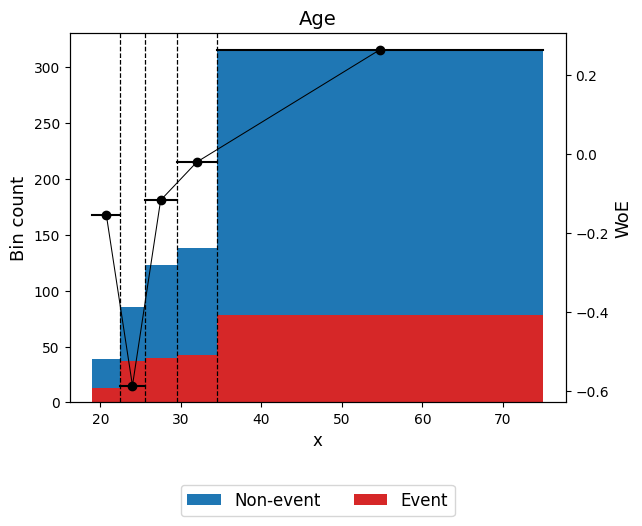

📊 Variabile: Credit_Amount
Status: OPTIMAL
Splits: [ 959.5 1373.  3444.  3913.5 7760.5]
                       Bin  Count  Count (%)  Non-event  Event  Event rate  \
0           (-inf, 959.50)     84   0.120000         53     31    0.369048   
1        [959.50, 1373.00)     95   0.135714         69     26    0.273684   
2       [1373.00, 3444.00)    302   0.431429        226     76    0.251656   
3       [3444.00, 3913.50)     38   0.054286         36      2    0.052632   
4       [3913.50, 7760.50)    130   0.185714         82     48    0.369231   
5           [7760.50, inf)     51   0.072857         24     27    0.529412   
6                  Special      0   0.000000          0      0    0.000000   
7                  Missing      0   0.000000          0      0    0.000000   
Totals                        700   1.000000        490    210    0.300000   

             WoE        IV        JS  
0      -0.310993  0.012270  0.001528  
1       0.128712  0.002189  0.000273  
2       0.2425

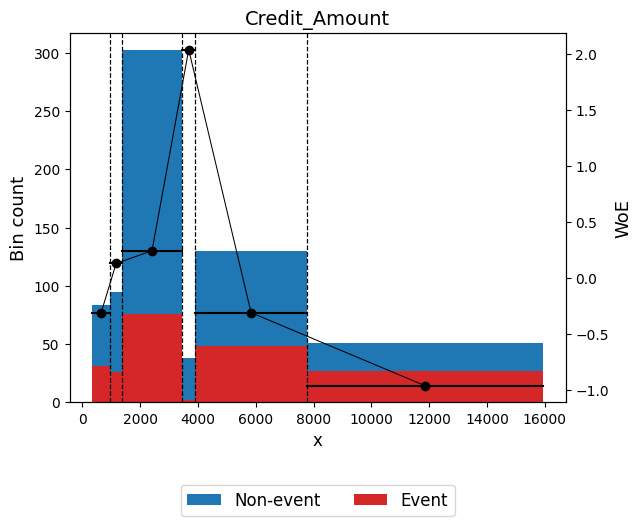

📊 Variabile: Duration_Months
Status: OPTIMAL
Splits: [ 8.5 11.5 16.5 34.5 47.5]
                   Bin  Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 8.50)     66   0.094286         60      6    0.090909   
1        [8.50, 11.50)     63   0.090000         50     13    0.206349   
2       [11.50, 16.50)    180   0.257143        135     45    0.250000   
3       [16.50, 34.50)    272   0.388571        180     92    0.338235   
4       [34.50, 47.50)     76   0.108571         45     31    0.407895   
5         [47.50, inf)     43   0.061429         20     23    0.534884   
6              Special      0   0.000000          0      0    0.000000   
7              Missing      0   0.000000          0      0    0.000000   
Totals                    700   1.000000        490    210    0.300000   

             WoE        IV        JS  
0       1.455287  0.136619  0.015714  
1       0.499776  0.020059  0.002482  
2       0.251314  0.015387  0.001918  
3       -0.17613  0.012

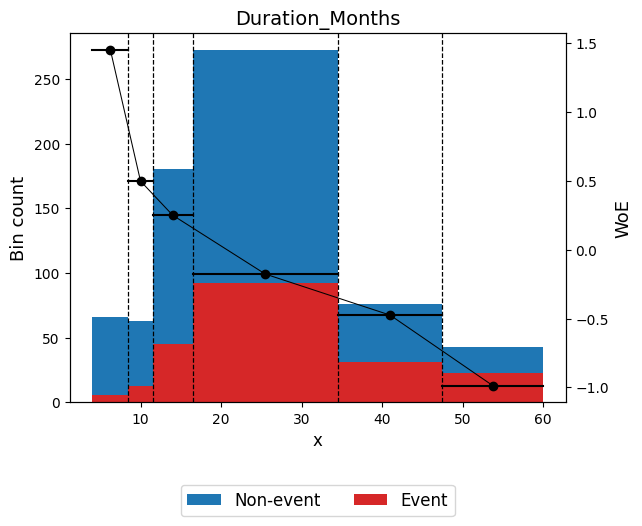

In [19]:
#VISUALIZZAZIONE DEI BINNING FATTI PER LE VARIABILI NUMERICHE
import matplotlib.pyplot as plt

for var in ["Age", "Credit_Amount", "Duration_Months"]:
    print("="*60)
    print(f"📊 Variabile: {var}")
    print("="*60)
    
    # estrai oggetto OptimalBinning relativo a quella variabile
    bv = binning_process.get_binned_variable(var)
    
    # status
    print("Status:", bv.status)
    
    # cutpoint
    print("Splits:", bv.splits)
    
    # tabella WoE/IV
    table = bv.binning_table.build()
    print(table)
    
  
    # grafico WoE
    bv.binning_table.plot(metric="woe", style="actual", add_special=False, add_missing=False)
    plt.show()


In [20]:
# Check Per vedere se tutte le variabili sono state trasformate in WOE e se quindi sono tutte numeriche.
pd.set_option("display.max_columns", None)
print(X_train_woe.head())



     Status_Checking_Account  Duration_Months  Credit_History   Purpose  \
10                 -0.415165         0.251314       -0.082842 -0.180353   
82                  1.184134        -0.176130       -0.082842 -0.241162   
827                 1.184134        -0.176130       -1.090920 -0.241162   
410                -0.415165        -0.176130       -0.082842  0.384846   
48                  1.184134         0.499776        0.699082 -0.180353   

     Credit_Amount  Savings_Account_Bonds  Employment_Since  Installment_Rate  \
10        0.128712              -0.301787         -0.579034         -0.100083   
82        0.242504              -0.098061          0.074691         -0.100083   
827      -0.311780              -0.301787          0.074691          0.211784   
410       0.242504              -0.301787          0.194156         -0.149489   
48       -0.311780              -0.301787          0.074691          0.292136   

     Personal_Status_Sex  Other_Debtors  Present_Residence_Sin

In [21]:
# mostra il tipo di ogni colonna
print(X_train_woe.dtypes)


Status_Checking_Account    float64
Duration_Months            float64
Credit_History             float64
Purpose                    float64
Credit_Amount              float64
Savings_Account_Bonds      float64
Employment_Since           float64
Installment_Rate           float64
Personal_Status_Sex        float64
Other_Debtors              float64
Present_Residence_Since    float64
Property                   float64
Age                        float64
Other_Installment_Plans    float64
Number_Credits             float64
Job                        float64
People_Liable              float64
Telephone                  float64
dtype: object


In [22]:
#FULL MODEL LOGISTIC
import statsmodels.api as sm

# aggiungi l’intercetta
X_train_sm = sm.add_constant(X_train_woe)
X_test_sm  = sm.add_constant(X_test_woe)

# stima modello
logit_model = sm.Logit(y_train2, X_train_sm)
result = logit_model.fit()

# riepilogo statistico
print(result.summary2())


         Current function value: 0.498465
         Iterations: 35
                                                Results: Logit
Model:                             Logit                           Method:                          MLE       
Dependent Variable:                default                         Pseudo R-squared:                0.184     
Date:                              2025-11-18 19:06                AIC:                             731.8511  
No. Observations:                  700                             BIC:                             809.2195  
Df Model:                          16                              Log-Likelihood:                  -348.93   
Df Residuals:                      683                             LL-Null:                         -427.61   
Converged:                         0.0000                          LLR p-value:                     2.7443e-25
No. Iterations:                    35.0000                         Scale:                     

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



In [23]:
vars_keep = [c for c in X_train_woe.columns if c not in 
             ["Other_Debtors","People_Liable","Telephone","Number_Credits"]]
X_train_sm2 = sm.add_constant(X_train_woe[vars_keep], has_constant="add")
X_test_sm2  = sm.add_constant(X_test_woe[vars_keep], has_constant="add")
res2 = sm.Logit(y_train2, X_train_sm2).fit()
print(res2.summary2())


Optimization terminated successfully.
         Current function value: 0.445136
         Iterations 7
                            Results: Logit
Model:                Logit              Method:             MLE       
Dependent Variable:   default            Pseudo R-squared:   0.271     
Date:                 2025-11-18 19:06   AIC:                653.1901  
No. Observations:     700                BIC:                721.4563  
Df Model:             14                 Log-Likelihood:     -311.60   
Df Residuals:         685                LL-Null:            -427.61   
Converged:            1.0000             LLR p-value:        1.4791e-41
No. Iterations:       7.0000             Scale:              1.0000    
-----------------------------------------------------------------------
                         Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
-----------------------------------------------------------------------
const                   -0.8610   0.1029 -8.3695 0.0000 -1.0626

In [24]:
# variabili da escludere
drop_vars = ["Present_Residence_Since", "Job", "Age", "Property","Other_Debtors","People_Liable","Telephone","Number_Credits"]

# tieni solo le altre
vars_keep = [c for c in X_train_woe.columns if c not in drop_vars]

# rifit logistica
X_train_sm3 = sm.add_constant(X_train_woe[vars_keep], has_constant="add")
X_test_sm3  = sm.add_constant(X_test_woe[vars_keep],  has_constant="add")

# LOGISTICA NON PESATA 
glm3 = sm.GLM(
    y_train2,
    X_train_sm3,
    family=sm.families.Binomial(sm.families.links.logit())
)
res3 = glm3.fit()
print(res3.summary())



                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:                  700
Model:                            GLM   Df Residuals:                      689
Model Family:                Binomial   Df Model:                           10
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -314.67
Date:                Tue, 18 Nov 2025   Deviance:                       629.35
Time:                        19:06:33   Pearson chi2:                     739.
No. Iterations:                     6   Pseudo R-squ. (CS):             0.2758
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [25]:
#LOGISTICA PESATA 

import statsmodels.api as sm
import numpy as np
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

# 1. Definisci pesi (0:1, 1:2)
weights_train = np.where(y_train2 == 1, 2.0, 1.0)

# 2. Aggiungi costante
X_train_sm_w = sm.add_constant(X_train_woe[vars_keep], has_constant="add")
X_test_sm_w  = sm.add_constant(X_test_woe[vars_keep],  has_constant="add")

# 3. Fit GLM binomiale (equivalente alla logistica) con pesi
glm_w = sm.GLM(
    y_train2,
    X_train_sm_w,
    family=sm.families.Binomial(),
    freq_weights=weights_train
)
res_w = glm_w.fit()

# 4. Riepilogo risultati
print(res_w.summary())



                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:                  700
Model:                            GLM   Df Residuals:                      899
Model Family:                Binomial   Df Model:                           10
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -452.97
Date:                Tue, 18 Nov 2025   Deviance:                       905.94
Time:                        19:06:38   Pearson chi2:                     993.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.3936
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [28]:

from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

# probabilità predette
y_pred_test_log_w = res_w.predict(X_test_sm_w)

# metriche
print("AUC test (pesata):", roc_auc_score(y_test2, y_pred_test_log_w))
print("F1 test (cutoff=0.5):", f1_score(y_test2, (y_pred_test_log_w >= 0.5).astype(int)))

# matrice di confusione
print("Confusion matrix (cutoff=0.5):\n", confusion_matrix(y_test2, (y_pred_test_log_w >= 0.5).astype(int)))


AUC test (senza Status_Checking_Account):  0.7788359788359788
Confusion matrix (cutoff=0.5):
 [[160  50]
 [ 30  60]]


In [ ]:
####MATRICI DI CONFUSIONE DI EBM E LOGISTICA UTILIZZANDO IL CUTOFF Con criterio di youlden

Cutoff Youden: 0.4708676090108548
Confusion matrix LOGISTICA (cutoff Youden):
 [[156  54]
 [ 24  66]]


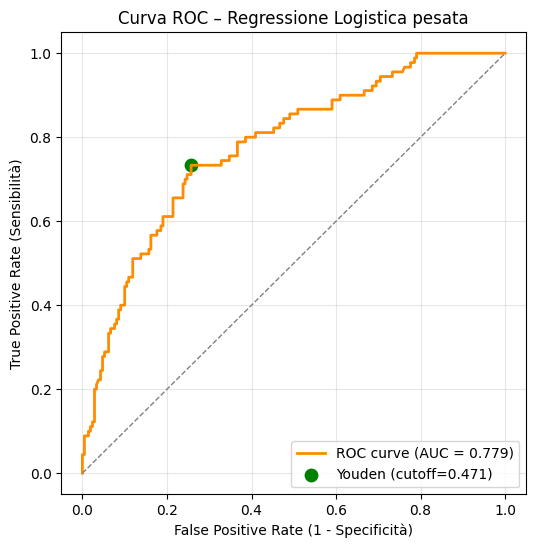

In [239]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test2, y_pred_test_log_w)
youden_index = np.argmax(tpr - fpr)
cutoff_youden = thresholds[youden_index]
print("Cutoff Youden:", cutoff_youden)
print("Confusion matrix LOGISTICA (cutoff Youden):\n", confusion_matrix(y_test2, (y_pred_test_log_w >= 0.4044).astype(int)))

# Calcola ROC e AUC
fpr, tpr, thresholds = roc_curve(y_test2, y_pred_test_log_w)
roc_auc = auc(fpr, tpr)

# Calcola indice di Youden e cutoff
youden_index = np.argmax(tpr - fpr)
cutoff_youden = thresholds[youden_index]

# Coordinate del punto di Youden
x_youden = fpr[youden_index]
y_youden = tpr[youden_index]

# Grafico ROC
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)

# Punto di Youden
plt.scatter(x_youden, y_youden, color='green', s=80, label=f'Youden (cutoff={cutoff_youden:.3f})')

plt.xlabel('False Positive Rate (1 - Specificità)')
plt.ylabel('True Positive Rate (Sensibilità)')
plt.title('Curva ROC – Regressione Logistica pesata')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


Cutoff Youden EBM: 0.4222545696628317
Confusion matrix EBM (cutoff Youden):
 [[137  73]
 [ 12  78]]


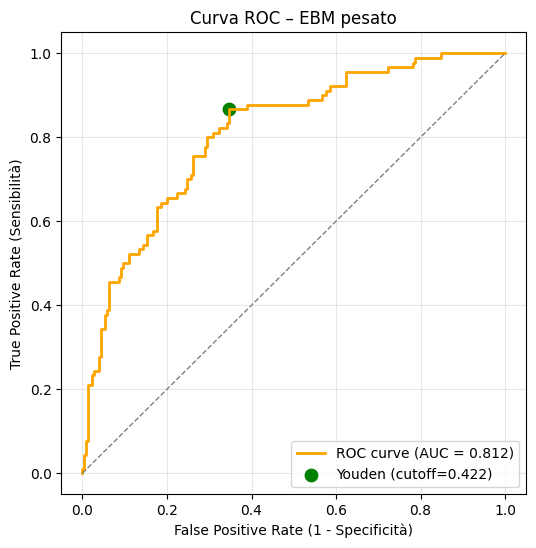

In [26]:
from sklearn.metrics import roc_curve, confusion_matrix, auc
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Calcolo del cutoff di Youden ---
fpr_ebm, tpr_ebm, thresholds_ebm = roc_curve(y_test, y_prob_ebm)
youden_index_ebm = np.argmax(tpr_ebm - fpr_ebm)
cutoff_youden_ebm = thresholds_ebm[youden_index_ebm]

print("Cutoff Youden EBM:", cutoff_youden_ebm)

# --- 2. Matrice di confusione con cutoff di Youden ---
print("Confusion matrix EBM (cutoff Youden):\n",
      confusion_matrix(y_test, (y_prob_ebm >= cutoff_youden_ebm).astype(int)))

# --- 3. Grafico ROC con punto di Youden ---
roc_auc_ebm = auc(fpr_ebm, tpr_ebm)
x_youden = fpr_ebm[youden_index_ebm]
y_youden = tpr_ebm[youden_index_ebm]

plt.figure(figsize=(6,6))
plt.plot(fpr_ebm, tpr_ebm, color='orange', lw=2, label=f'ROC curve (AUC = {roc_auc_ebm:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
plt.scatter(x_youden, y_youden, color='green', s=80, label=f'Youden (cutoff={cutoff_youden_ebm:.3f})')

plt.xlabel('False Positive Rate (1 - Specificità)')
plt.ylabel('True Positive Rate (Sensibilità)')
plt.title('Curva ROC – EBM pesato')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


In [ ]:
###Esempio di Scorecard Logistica

In [64]:
import numpy as np
import pandas as pd

# ================================================================
# 1️⃣ PARAMETRI BASE DELLA SCALATURA  (coerenti con PD ≈ 30%)
# ================================================================

# Punteggio di riferimento (scala leggibile, centrato sul rischio medio)
target_points_at_odds = 600     # score medio
target_odds = 2.33              # odds reali (70% good / 30% bad)
pdo = 20                        # Points to Double the Odds (standard)

# Calcolo dei parametri di scala
factor = pdo / np.log(2)
offset = target_points_at_odds - factor * np.log(target_odds)

print("=== Parametri di scalatura ===")
print(f"Target odds: {target_odds:.2f} : 1")
print(f"PDO (Points to Double the Odds): {pdo}")
print(f"Factor: {factor:.2f}")
print(f"Offset: {offset:.2f}")

# ================================================================
# 2️⃣ COSTRUZIONE DELLA SCORECARD
# ================================================================


scorecard_tables = []

for var in vars_keep:
    beta = res_w.params[var]
    bv = binning_process.get_binned_variable(var)
    table = bv.binning_table.build()[["Bin", "WoE"]]

    # Conversione robusta del WoE
    table["WoE"] = pd.to_numeric(table["WoE"], errors="coerce").fillna(0)

    # Escludere eventuali bin "Special" o "Missing"
    table = table[~table["Bin"].isin(["Special", "Missing"])]

    # Calcolo dei punti per ciascun bin
    table["Points"] = - beta * table["WoE"] * factor

    # Aggiungo tabella variabile/coefficienti
    table["Beta"] = beta
    table["Variable"] = var

    # Riordino le colonne
    scorecard_tables.append(table[["Variable", "Bin", "WoE", "Beta", "Points"]])

# Unisce tutte le tabelle in un unico DataFrame
scorecard_df = pd.concat(scorecard_tables, ignore_index=True)

# Arrotondo i valori per leggibilità
scorecard_df_rounded = scorecard_df.copy()
scorecard_df_rounded["WoE"] = scorecard_df_rounded["WoE"].round(3)
scorecard_df_rounded["Beta"] = scorecard_df_rounded["Beta"].round(3)
scorecard_df_rounded["Points"] = scorecard_df_rounded["Points"].round(2)

pd.set_option("display.width", None)
pd.set_option("display.max_columns", None)

print("\n=== Esempio tabella scorecard (prime 16 righe) ===")
print(scorecard_df_rounded.head(16))

# ================================================================
# 3️⃣ CALCOLO DEI PUNTEGGI TOTALI PER I CLIENTI
# ================================================================
# Formula: Score = Offset − Factor × logit(p)
# dove logit(p) = Xβ

logit_train = np.dot(X_train_sm3, res_w.params)
scores = offset - factor * logit_train

# Range complessivo dei punteggi
print("\n=== Range dei punteggi calcolati ===")
print("Min:", scores.min())
print("Max:", scores.max())
print("Media:", scores.mean())

# Esempio di punteggi
print("\n=== Esempio di 5 punteggi calcolati ===")
print(scores[:5])


=== Parametri di scalatura ===
Target odds: 2.33 : 1
PDO (Points to Double the Odds): 20
Factor: 28.85
Offset: 575.59

=== Esempio tabella scorecard (prime 16 righe) ===
                   Variable                       Bin    WoE   Beta  Points
0   Status_Checking_Account              [no account]  1.184 -0.847   28.94
1   Status_Checking_Account       [>=200 DM / salary]  0.134 -0.847    3.26
2   Status_Checking_Account                [0-200 DM] -0.415 -0.847  -10.15
3   Status_Checking_Account                   [<0 DM] -0.764 -0.847  -18.67
4   Status_Checking_Account                            0.000 -0.847    0.00
5           Duration_Months              (-inf, 8.50)  1.455 -0.992   41.66
6           Duration_Months             [8.50, 11.50)  0.500 -0.992   14.31
7           Duration_Months            [11.50, 16.50)  0.251 -0.992    7.19
8           Duration_Months            [16.50, 34.50) -0.176 -0.992   -5.04
9           Duration_Months            [34.50, 47.50) -0.475 -0.992  -

In [67]:
import pandas as pd
import numpy as np

# ================================================================
# 🔹 1️⃣ Calcolo del contributo medio (|beta| * sd(WOE))
# ================================================================

impacts = []

for var in vars_keep:
    beta = abs(res_w.params[var])  # coefficiente stimato (in valore assoluto)
    
    # Recupera la tabella dei bin della variabile
    bv = binning_process.get_binned_variable(var)
    table = bv.binning_table.build()[["Bin", "WoE"]]
    
    # Conversione robusta a numerico
    table["WoE"] = pd.to_numeric(table["WoE"], errors="coerce")
    
    # Escludi eventuali bin "Special" o "Missing"
    table = table[~table["Bin"].isin(["Special", "Missing"])]
    
    # Calcola la deviazione standard dei WOE
    woe_std = table["WoE"].std()
    
    # Calcola il contributo medio della variabile
    impact = beta * woe_std
    
    impacts.append({
        "Variable": var,
        "Beta_abs": beta,
        "WOE_std": woe_std,
        "Impact": impact
    })

# Crea DataFrame ordinato per contributo medio
impacts_df = pd.DataFrame(impacts)
impacts_df = impacts_df.sort_values("Impact", ascending=False).reset_index(drop=True)

# ================================================================
# 🔹 2️⃣ Output pulito e leggibile
# ================================================================
impacts_df_rounded = impacts_df.round(4)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
print(impacts_df_rounded)

# Mostra le prime 10 variabili più influenti
print("\n Variabili più influenti sul logit:")
print(impacts_df_rounded.head(10))


                  Variable  Beta_abs  WOE_std  Impact
0            Credit_Amount    0.9582   1.0258  0.9829
1          Duration_Months    0.9922   0.8494  0.8428
2  Status_Checking_Account    0.8471   0.8507  0.7206
3                  Purpose    1.0714   0.5168  0.5537
4           Credit_History    0.7540   0.7328  0.5525
5    Savings_Account_Bonds    0.8025   0.5974  0.4794
6         Employment_Since    0.8118   0.5170  0.4197
7  Other_Installment_Plans    0.8176   0.4606  0.3766
8         Installment_Rate    1.5982   0.2209  0.3530
9      Personal_Status_Sex    1.3597   0.2341  0.3183

 Variabili più influenti sul logit:
                  Variable  Beta_abs  WOE_std  Impact
0            Credit_Amount    0.9582   1.0258  0.9829
1          Duration_Months    0.9922   0.8494  0.8428
2  Status_Checking_Account    0.8471   0.8507  0.7206
3                  Purpose    1.0714   0.5168  0.5537
4           Credit_History    0.7540   0.7328  0.5525
5    Savings_Account_Bonds    0.8025   0.5974

In [38]:
## CREAZIONE TABELLA RIEPILOGATIVA METRICHE ##

from sklearn.metrics import (
    accuracy_score, recall_score,
    roc_auc_score, confusion_matrix
)
import pandas as pd

# ================================================================
#  cutoff reali stimati (criterio di Youden)
# ================================================================
cutoff_logit = 0.4708
cutoff_ebm   = 0.4222

# ================================================================
#  Calcolo delle probabilità stimate
# ================================================================
# LOGISTICA
y_prob_logit = p_test_no_dm
y_pred_logit = (y_prob_logit >= cutoff_logit).astype(int)

# EBM
y_prob_ebm = y_prob_ebm
y_pred_ebm = (y_prob_ebm >= cutoff_ebm).astype(int)


# ================================================================
#  calcolo delle metriche
# ================================================================
def model_metrics(y_true, y_pred, y_prob, model_name):
    # Matrice di confusione: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    # Calcolo della specificità
    specificity = tn / (tn + fp)

    return {
        "Modello": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensibilità (Recall 1)": recall_score(y_true, y_pred, pos_label=1),
        "Specificità (0)": specificity,
        "AUC": roc_auc_score(y_true, y_prob),
        "Precision (1)": precision_score(y_true, y_pred, pos_label=1)
        
    }

# ================================================================
#  Calcolo metriche per entrambi i modelli
# ================================================================
results = []

# Logistica ( y_test2)
results.append(model_metrics(y_test2, y_pred_logit, y_prob_logit, "Regressione logistica"))

# EBM ( y_test)
results.append(model_metrics(y_test, y_pred_ebm, y_prob_ebm, "Explainable Boosting Machine"))

# ================================================================
#  Tabella finale
# ================================================================
results_df = pd.DataFrame(results)
results_df = results_df.round(4)
results_df = results_df[[
    "Modello", "Accuracy", "Sensibilità (Recall 1)",
    "Specificità (0)", "AUC", "Precision (1)"
]]

print("\n Confronto modelli – Dataset German Credit (Cut-off Youden)")
print(results_df)



 Confronto modelli – Dataset German Credit (Cut-off Youden)
                        Modello  Accuracy  Sensibilità (Recall 1)  \
0         Regressione logistica    0.7400                  0.7333   
1  Explainable Boosting Machine    0.7167                  0.8667   

   Specificità (0)     AUC  Precision (1)  
0           0.7429  0.7788         0.5500  
1           0.6524  0.8115         0.5166  


In [30]:
# --- Tabella comparativa ---
comparison = pd.DataFrame({
    "Modello": ["Logistica", "EBM"],
    "AUC": [0.7788, 0.8115],
    "Accuracy": [0.7400, 0.7167],
    "Sensibilità (Recall 1)": [0.7333, 0.8667],
    "Specificità (Recall 0)": [0.7429, 0.6524],
    "Precision (1)": [0.5500, 0.5166]
    
})
print("\n=== Confronto finale Logistica vs EBM ===")
display(comparison.round(3))

import numpy as np

# Valori della tua matrice di confusione
cm = np.array([[156, 54],
               [ 24, 66]])


print("Matrice di confusione LOGISTICA (cutoff Youden):")
print(cm)

print("Matrice di confusione EBM(cutoff Youden):\n",
      confusion_matrix(y_test, (y_prob_ebm >= 0.4222).astype(int)))


=== Confronto finale Logistica vs EBM ===


,Modello,AUC,Accuracy,Sensibilità (Recall 1),Specificità (Recall 0),Precision (1)
0,Logistica,0.779,0.740,0.733,0.743,0.550
1,EBM,0.812,0.717,0.867,0.652,0.517


Matrice di confusione LOGISTICA (cutoff Youden):
[[156  54]
 [ 24  66]]
Matrice di confusione EBM(cutoff Youden):
 [[131  79]
 [ 12  78]]


Cutoff Youden EBM: 0.4762690567631253
Confusion matrix EBM (cutoff Youden):
 [[148  62]
 [ 18  72]]


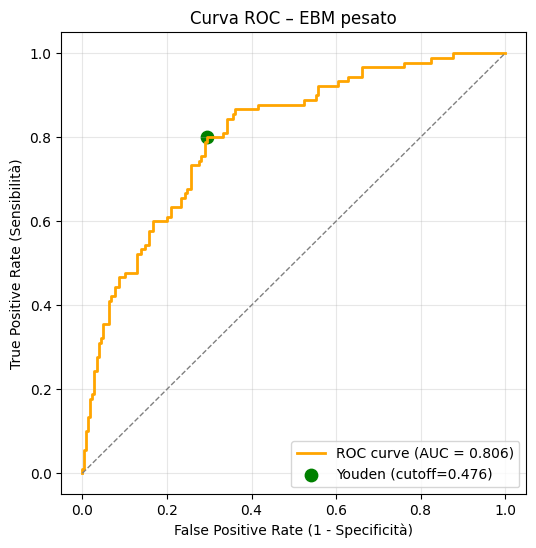

In [26]:


from sklearn.metrics import roc_curve, confusion_matrix, auc
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Calcolo del cutoff di Youden ---
fpr_ebm, tpr_ebm, thresholds_ebm = roc_curve(y_test, y_prob_ebm)
youden_index_ebm = np.argmax(tpr_ebm - fpr_ebm)
cutoff_youden_ebm = thresholds_ebm[youden_index_ebm]

print("Cutoff Youden EBM:", cutoff_youden_ebm)

# --- 2. Matrice di confusione con cutoff di Youden ---
print("Confusion matrix EBM (cutoff Youden):\n",
      confusion_matrix(y_test, (y_prob_ebm >= cutoff_youden_ebm).astype(int)))

# --- 3. Grafico ROC con punto di Youden ---
roc_auc_ebm = auc(fpr_ebm, tpr_ebm)
x_youden = fpr_ebm[youden_index_ebm]
y_youden = tpr_ebm[youden_index_ebm]

plt.figure(figsize=(6,6))
plt.plot(fpr_ebm, tpr_ebm, color='orange', lw=2, label=f'ROC curve (AUC = {roc_auc_ebm:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
plt.scatter(x_youden, y_youden, color='green', s=80, label=f'Youden (cutoff={cutoff_youden_ebm:.3f})')

plt.xlabel('False Positive Rate (1 - Specificità)')
plt.ylabel('True Positive Rate (Sensibilità)')
plt.title('Curva ROC – EBM pesato')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()